# Carga y descripción del dataset

In [1]:
# Librerías
import mlflow
import mlflow.sklearn

import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns

from mlflow.models import infer_signature

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.metrics import geometric_mean_score

c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Importar dataset
df = pd.read_csv('../data/raw/bedtime_screentime_sleep_debt.csv')

In [3]:
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


## Descripción del dataset

El dataset contiene **8,500** registros y **18 variables** relacionadas con características demográficas, hábitos nocturnos de uso del teléfono, estilo de vida y características del sueño. La variable `sleep_debt_category` se usará como variable objetivo de un problema de clasificación multiclase.


---



---



| Variable | Tipo | Descripción | Valores observados |
|---|---|---|---|
| `user_id` | Categórica / identificador | Identificador único de cada registro. | 8,500 valores únicos, con formato `USR-00001`. |
| `age` | Numérica discreta | Edad de la persona en años. | **18–65 años**. |
| `gender` | Categórica nominal | Género registrado de la persona. | `Female`, `Male`, `Non-Binary`. |
| `occupation_type` | Categórica nominal | Ocupación o modalidad laboral. | `Corporate 9-to-5`, `Remote Tech`, `Student`, `Healthcare / Shift Worker`, `Freelance / Creative`. |
| `chronotype` | Categórica | Preferencia de horario de actividad. | `Morning Lark`, `Intermediate`, `Night Owl`. |
| `bedtime_phone_minutes` | Numérica discreta | Tiempo de uso del teléfono asociado al periodo previo a dormir. | **1–180 min**. |
| `primary_bedtime_app` | Categórica nominal | Principal tipo de aplicación utilizada antes de dormir. | 6 categorías: `TikTok / Reels`, `YouTube`, `Instagram / Reddit`, `Streaming (Netflix/Hulu)`, `Messaging / Chat`, `News / Reading`. |
| `screen_brightness_pct` | Numérica discreta | Nivel de brillo de la pantalla. | **10–100 %**. |
| `blue_light_filter_active` | Binaria | Indica el estado del filtro de luz azul. | `0` = desactivado; `1` = activado. |
| `caffeine_post_5pm_mg` | Numérica discreta | Cantidad registrada de cafeína consumida después de las 5 p. m. | **0–250 mg**. `0` = ausencia de consumo registrado. |
| `physical_activity_min` | Numérica discreta | Minutos registrados de actividad física. | **0–112 min**. |
| `sleep_latency_min` | Numérica continua | Tiempo transcurrido hasta conciliar el sueño. | **6.0–124 min**. |
| `total_sleep_hours` | Numérica continua | Duración total del sueño. | **3.2–9.8 h**. |
| `deep_sleep_pct` | Numérica continua | Porcentaje correspondiente al sueño profundo. | **8.1–28.0 %**. |
| `rem_sleep_pct` | Numérica continua | Porcentaje correspondiente al sueño REM. | **9.6–27.0 %**. |
| `morning_alarm_snoozes` | Numérica discreta | Número de veces que se pospone la alarma. | **0–7 veces**. |
| `next_day_fatigue_score` | Numérica continua | Puntuación de fatiga registrada al día siguiente. | **1.0–10.0**. |
| `sleep_debt_category` | Categórica ordinal / objetivo | Clasificación del nivel de deuda o recuperación del sueño. | `Optimal Recovery`, `Mild Deficit`, `Moderate Debt`, `Severe Sleep Debt`. **Variable objetivo para clasificación.** |

**Fuente:** Kaggle

In [4]:
print('Dimensión del DataFrame',df.shape)

Dimensión del DataFrame (8500, 18)


Se cargó correctamente el dataset. Tenemos **8,500 registros y 18 columnas**.

In [5]:
df.columns

Index(['user_id', 'age', 'gender', 'occupation_type', 'chronotype',
       'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'next_day_fatigue_score', 'sleep_debt_category'],
      dtype='str')

# Limpieza de datos

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   str    
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   str    
 3   occupation_type           8500 non-null   str    
 4   chronotype                8500 non-null   str    
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   str    
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_sleep_pct      

La variable `user_id` no aporta información relevante al análisis exploratorio de datos ni al entrenamiento del modelo, por lo que podemos eliminarla.

También se decidió excluir `next_day_fatigue_score`, pues representa información posterior y estrechamente relacionada con la deuda de sueño. Incluirla como variable predictora podría facilitar artificialmente la clasificación y no representaría el objetivo del modelo, que busca predecir la categoría de deuda de sueño a partir de los hábitos y características previas.

In [7]:
df = df.drop(["user_id","next_day_fatigue_score"], axis=1)

## Valores faltantes y duplicados

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       8500 non-null   int64  
 1   gender                    8500 non-null   str    
 2   occupation_type           8500 non-null   str    
 3   chronotype                8500 non-null   str    
 4   bedtime_phone_minutes     8500 non-null   int64  
 5   primary_bedtime_app       8500 non-null   str    
 6   screen_brightness_pct     8500 non-null   int64  
 7   blue_light_filter_active  8500 non-null   int64  
 8   caffeine_post_5pm_mg      8500 non-null   int64  
 9   physical_activity_min     8500 non-null   int64  
 10  sleep_latency_min         8500 non-null   float64
 11  total_sleep_hours         8500 non-null   float64
 12  deep_sleep_pct            8500 non-null   float64
 13  rem_sleep_pct             8500 non-null   float64
 14  morning_alarm_snooz

In [9]:
# Chequeo de duplicados
df.duplicated().sum()

np.int64(0)

Después de eliminar `user_id` y `next_day_fatigue_score`, el dataset quedó con **11 variables numéricas y 4 categóricas**, además de la variable objetivo (`sleep_debt_category`).

El dataset se encuentra limpio, **sin datos faltantes ni registros duplicados**.

## Tipos incorrectos

In [10]:
# Valores únicos y tipo de dato por columna
display(pd.DataFrame({
    "Valores únicos": df.nunique(),
    "Tipo de dato": df.dtypes
}))

,Valores únicos,Tipo de dato
age,48,int64
gender,3,str
occupation_type,5,str
chronotype,3,str
bedtime_phone_minutes,179,int64
primary_bedtime_app,6,str
screen_brightness_pct,91,int64
blue_light_filter_active,2,int64
caffeine_post_5pm_mg,218,int64
physical_activity_min,107,int64


Aquí se aprecia que `blue_light_filter_active` aparece como una variable numérica, pero solo tiene dos valores únicos (`0` y `1`). De acuerdo con la descripción del dataset, estos indican si el filtro de luz azul está desactivado o activado. Por lo tanto, se tratará como una **variable categórica binaria**.

In [11]:
df["blue_light_filter_active"] = pd.Categorical(
    df["blue_light_filter_active"],
    categories=[0, 1]
)

La variable objetivo `sleep_debt_category` aparece como tipo `str`, pero sus categorías tienen un orden según el nivel de deuda de sueño. Por esto, se convertirá en una **variable categórica ordinal**, ordenando sus valores desde `Optimal Recovery` hasta `Severe Sleep Debt`.

In [12]:
df["sleep_debt_category"] = pd.Categorical(
    df["sleep_debt_category"],
    categories=[
        "Optimal Recovery",
        "Mild Deficit",
        "Moderate Debt",
        "Severe Sleep Debt"
    ],
    ordered=True
)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   age                       8500 non-null   int64   
 1   gender                    8500 non-null   str     
 2   occupation_type           8500 non-null   str     
 3   chronotype                8500 non-null   str     
 4   bedtime_phone_minutes     8500 non-null   int64   
 5   primary_bedtime_app       8500 non-null   str     
 6   screen_brightness_pct     8500 non-null   int64   
 7   blue_light_filter_active  8500 non-null   category
 8   caffeine_post_5pm_mg      8500 non-null   int64   
 9   physical_activity_min     8500 non-null   int64   
 10  sleep_latency_min         8500 non-null   float64 
 11  total_sleep_hours         8500 non-null   float64 
 12  deep_sleep_pct            8500 non-null   float64 
 13  rem_sleep_pct             8500 non-null   float64 
 14  mor

Después de las transformaciones, el dataset quedó con **10 variables numéricas y 5 categóricas**, además de la variable objetivo (`sleep_debt_category`).

Para el  **tratamiento de outliers** , primero realizaremos el EDA y después se decidirá su tratamiento.

# Análisis exploratorio (EDA)

## Análisis univariado

In [14]:
# Variables numéricas y categóricas
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
display(num_cols)
cat_cols = df.select_dtypes(include=["str","category"]).columns.tolist()
display(cat_cols)

['age',
 'bedtime_phone_minutes',
 'screen_brightness_pct',
 'caffeine_post_5pm_mg',
 'physical_activity_min',
 'sleep_latency_min',
 'total_sleep_hours',
 'deep_sleep_pct',
 'rem_sleep_pct',
 'morning_alarm_snoozes']

['gender',
 'occupation_type',
 'chronotype',
 'primary_bedtime_app',
 'blue_light_filter_active',
 'sleep_debt_category']

In [15]:
# Estadísticas descriptivas
num_stats = df[num_cols].describe().T
# Calcula el sesgo
num_stats["Skew"] = df[num_cols].skew()
# Calcula la curtosis
num_stats["Kurt"] = df[num_cols].kurt()
num_stats

,count,mean,std,min,25%,50%,75%,max,Skew,Kurt
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0,0.684226,-0.347264
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0,1.030909,0.843917
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0,-0.006900,-0.389455
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0,1.782659,2.905376
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0,0.261986,-0.324080
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3,0.972772,1.094422
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8,-0.164325,-0.566224
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0,-0.261301,-0.054366
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0,-0.114800,0.066939
morning_alarm_snoozes,8500.0,2.766000,1.695407,0.0,2.00,3.00,4.00,7.0,0.342527,-0.415556


Las estadísticas descriptivas muestran diferencias importantes en la distribución de las variables. `screen_brightness_pct`, `total_sleep_hours`, `deep_sleep_pct`, `rem_sleep_pct`, `morning_alarm_snoozes` y `physical_activity_min` presentan distribuciones **aproximadamente simétricas**

Por otro lado, `age` y `sleep_latency_min` muestran un **sesgo positivo leve**. Por último, `bedtime_phone_minutes` y `caffeine_post_5pm_mg` presentan un **sesgo positivo fuerte**, especialmente `caffeine_post_5pm_mg`, que tiene un sesgo de **1.78**.

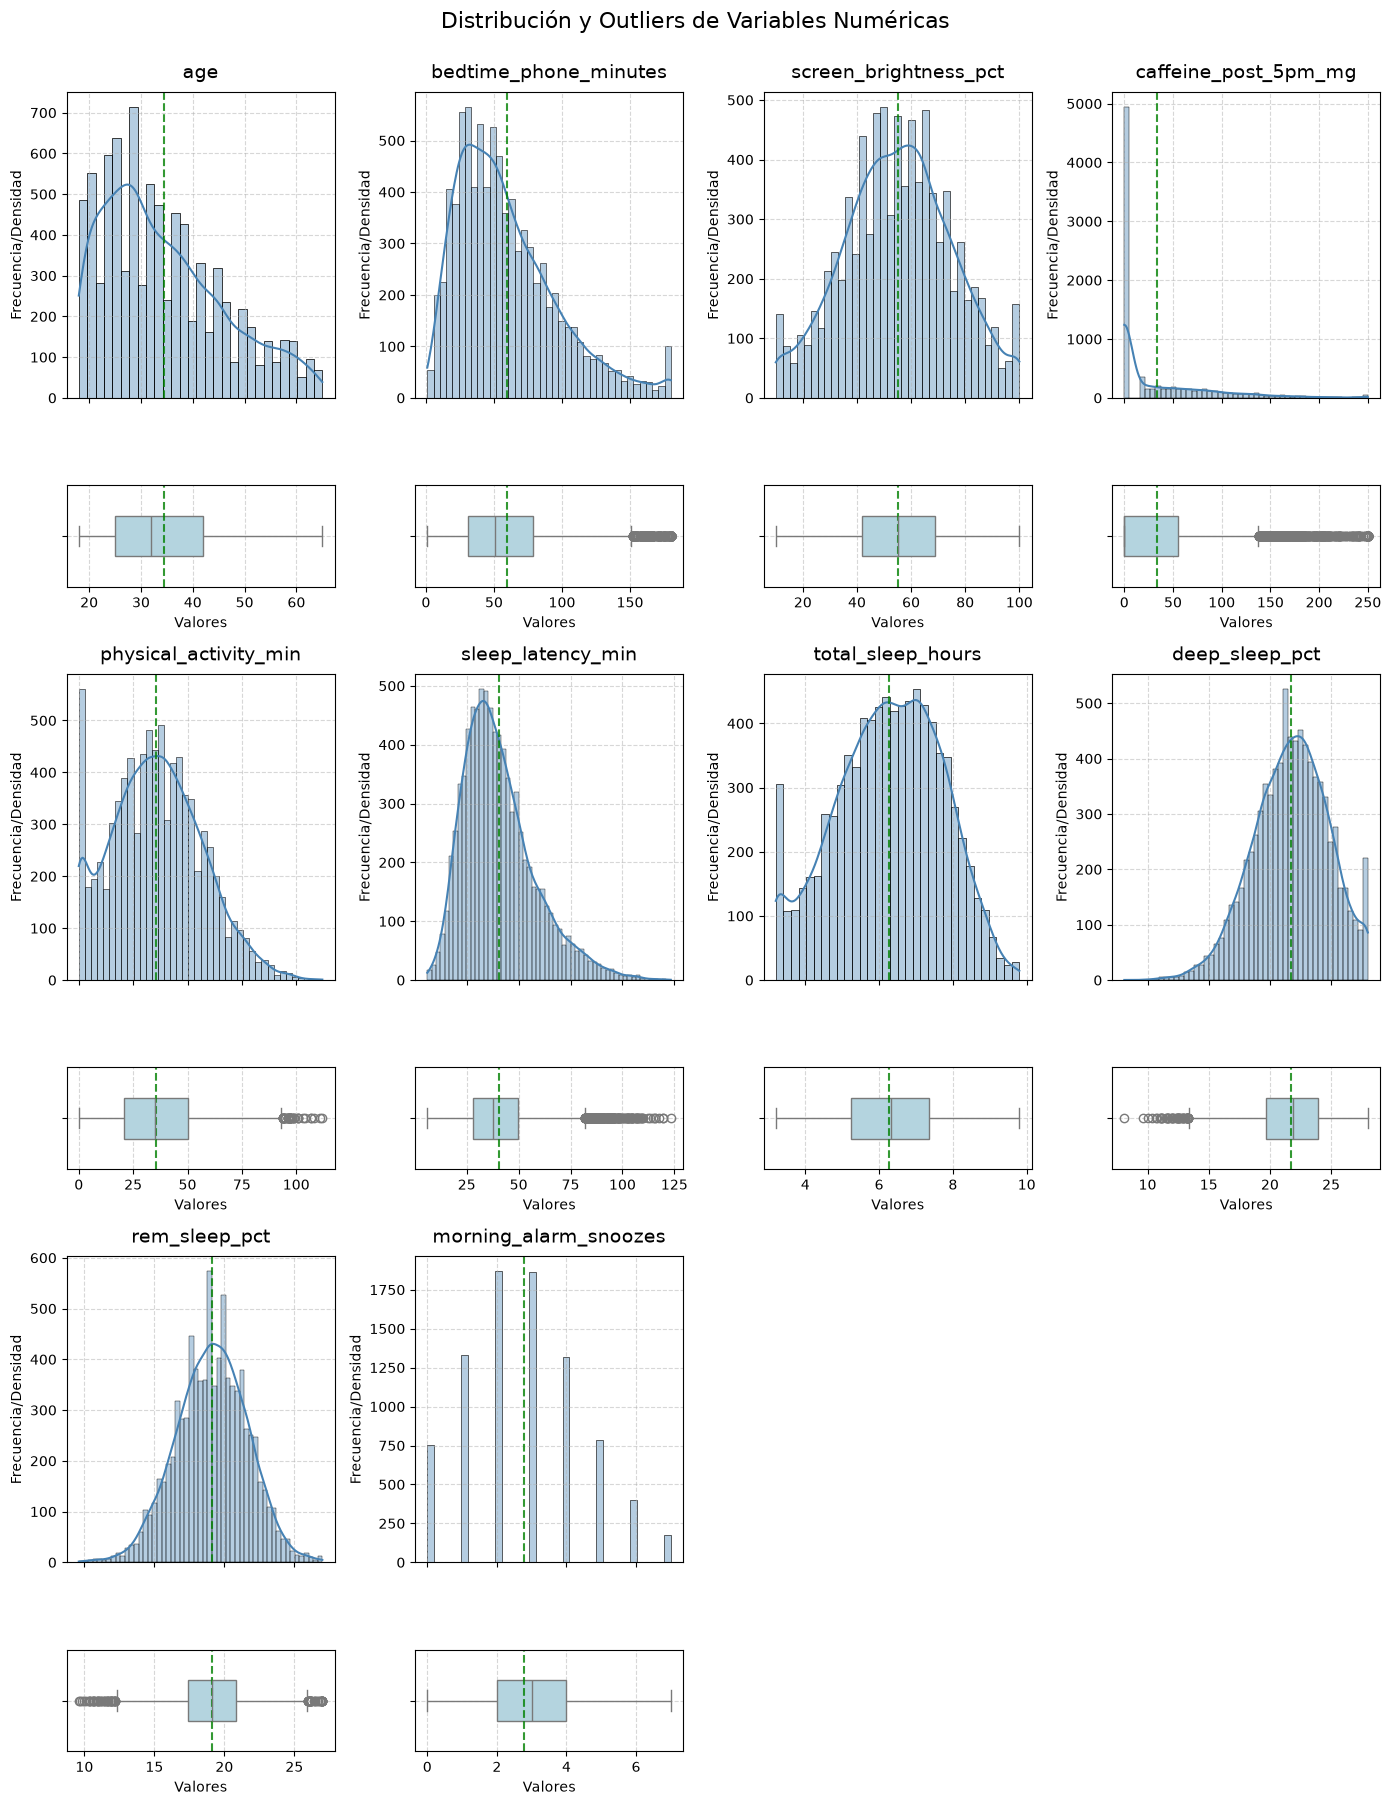

In [16]:
n_cols = 4
n_rows = math.ceil(len(num_cols) / n_cols)

# Multiplicamos las filas por 2. Cada variable usará un "bloque" de 2 subplots verticales
fig, axes = plt.subplots(
    nrows=n_rows * 2,
    ncols=n_cols,
    figsize=(14, 6 * n_rows),
    sharex=False,  # Se hace manualmente por columna
    gridspec_kw={
        "height_ratios": [3, 1] * n_rows
    },  # Alterna tamaños 3 para curvas, 1 para cajas
)

for i, col in enumerate(num_cols):
    # Calculo de la posición en la matriz de subplots
    col_idx = i % n_cols
    row_idx = (i // n_cols) * 2  # Salta de 2 en 2 filas

    # Definimos los dos subplots asignados a esta variable
    ax_curve = axes[row_idx, col_idx]
    ax_box = axes[row_idx + 1, col_idx]

    # Vincular manualmente el eje X del boxplot con la curva
    ax_box.sharex(ax_curve)

    # Quitar kde en morning_alarm_snoozes
    kde = col != "morning_alarm_snoozes"

    # Gráfico superior: Histograma + Curva de densidad
    sns.histplot(
        data=df, x=col, kde=kde, ax=ax_curve, color="steelblue", alpha=0.4
    )
    ax_curve.set_title(col, fontsize=14, pad=10)
    ax_curve.set_xlabel("")
    ax_curve.set_ylabel("Frecuencia/Densidad")
    ax_curve.tick_params(
        labelbottom=False
    )  # Quita los números del eje X intermedio
    ax_curve.grid(True, linestyle="--", alpha=0.5)

    # Gráfico inferior: Boxplot
    sns.boxplot(data=df, x=col, ax=ax_box, color="lightblue", width=0.4)
    ax_box.set_xlabel("Valores")
    ax_box.grid(True, linestyle="--", alpha=0.5)

    # Líneas de Media y Mediana*
    mediana = df[col].median()
    media = df[col].mean()
    for ax in [ax_curve, ax_box]:
         #ax.axvline(mediana, color='orange', linestyle='--', alpha=0.8)
         ax.axvline(media, color='green', linestyle='--', alpha=0.8)

# Eliminar cuadritos vacíos
for i in range(len(num_cols), n_rows * n_cols):
    col_idx = i % n_cols
    row_idx = (i // n_cols) * 2
    fig.delaxes(axes[row_idx, col_idx])
    fig.delaxes(axes[row_idx + 1, col_idx])

plt.suptitle(
    "Distribución y Outliers de Variables Numéricas", fontsize=16, y=1
)
plt.tight_layout()
plt.show()


Nota: la línea verde es la **Media**.


---


Se confirma visualmente lo que vimos en las estadísticas descriptivas sobre el sesgo de las variables.

En `caffeine_post_5pm_mg`, vemos que existe una alta concentración de registros con consumo igual a `0` y una cola hacia valores mayores.

También se observan concentraciones en `0` para `physical_activity_min`, mientras que `morning_alarm_snoozes` presenta una distribución discreta entre `0` y `7`.

## Outliers

Los boxplots permiten identificar posibles valores atípicos principalmente en `bedtime_phone_minutes`, `caffeine_post_5pm_mg`, `physical_activity_min`, `sleep_latency_min`, `deep_sleep_pct` y `rem_sleep_pct`.

Sin embargo, estos valores se encuentran dentro de los rangos definidos de cada variable y son consistentes con las distribuciones sesgadas observadas, por lo que **no se eliminarán**.

In [17]:
df[cat_cols].describe().T

,count,unique,top,freq
gender,8500,3,Female,4347
occupation_type,8500,5,Corporate 9-to-5,2838
chronotype,8500,3,Intermediate,3880
primary_bedtime_app,8500,6,TikTok / Reels,2198
blue_light_filter_active,8500,2,0,4524
sleep_debt_category,8500,4,Moderate Debt,4462


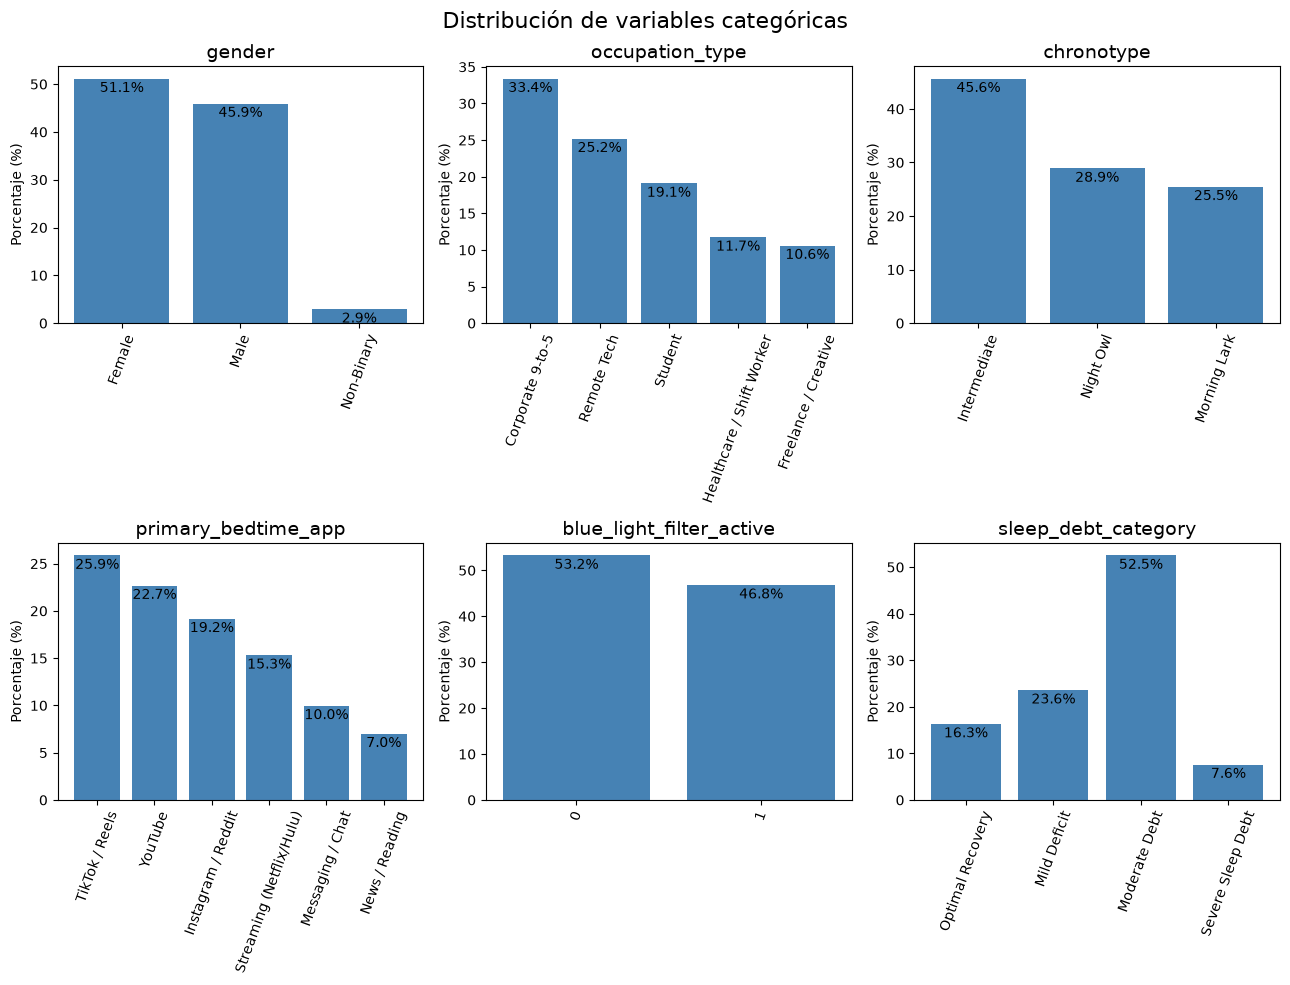

In [18]:
n_cols = 3
n_rows = math.ceil(len(cat_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    if col == "sleep_debt_category":
      freq_rel = (
        df[col]
        .value_counts(normalize=True, sort=False) # Respetar el orden
        * 100
      )
    else:
      freq_rel = df[col].value_counts(normalize=True) * 100
    # Guardamos el contenedor de las barras en una variable 'bars'
    bars = axes[i].bar(freq_rel.index, freq_rel.values, color="steelblue")
    # Poner porcentajes arriba de las barras
    axes[i].bar_label(bars, fmt="%.1f%%", padding=-12, fontsize=10)
    axes[i].set_title(col, fontsize=14)
    axes[i].set_ylabel("Porcentaje (%)")
    # Formato para blue_light_filter_active
    if col == "blue_light_filter_active": axes[i].set_xticks([0, 1]); axes[i].set_xticklabels(['0', '1'])
    axes[i].tick_params(axis='x',rotation=70)

# Eliminar espacios vacíos
for i in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle("Distribución de variables categóricas", fontsize=16)
plt.tight_layout()
plt.show()

Las variables categóricas tienen distribuciones variadas. `blue_light_filter_active` bastante equilibrada, mientras que en `gender`,`occupation_type`, `chronotype` y `primary_bedtime_app` algunas categorías aparecen con mayor frecuencia.

En la variable objetivo `sleep_debt_category` se observa un **desbalance de clases**. `Moderate Debt` representa aproximadamente el **52.5%** de los registros, mientras que `Severe Sleep Debt` solo el **7.6%**.

Este desbalance será importante al construir el **baseline**, ya que permitirá comparar posteriormente si el modelo realmente mejora sobre una predicción sencilla y evitar depender únicamente de métricas como `accuracy`.

## Análisis bivariado

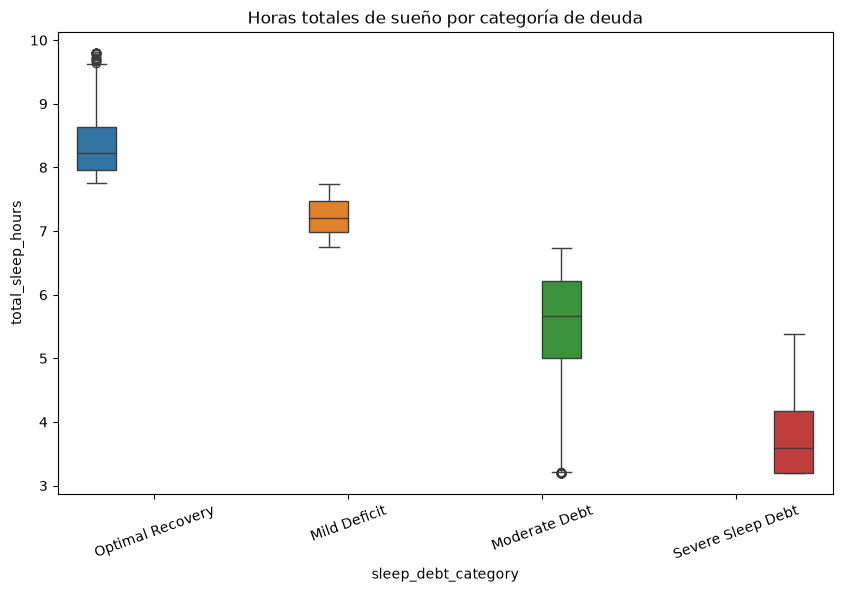

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='sleep_debt_category', y='total_sleep_hours', hue="sleep_debt_category")
plt.xticks(rotation=20)
plt.title("Horas totales de sueño por categoría de deuda")
plt.show()

Se ve que conforme aumenta la deuda de sueño, disminuyen las horas totales dormidas.

`Optimal Recovery` y `Mild Deficit` tienen valores más concentrados, mientras que en `Moderate Debt` y `Severe Sleep Debt` se observa mayor dispersión.

Por la separación entre las categorías, `total_sleep_hours` parece ser una variable importante para ayudar al modelo a diferenciar las clases.

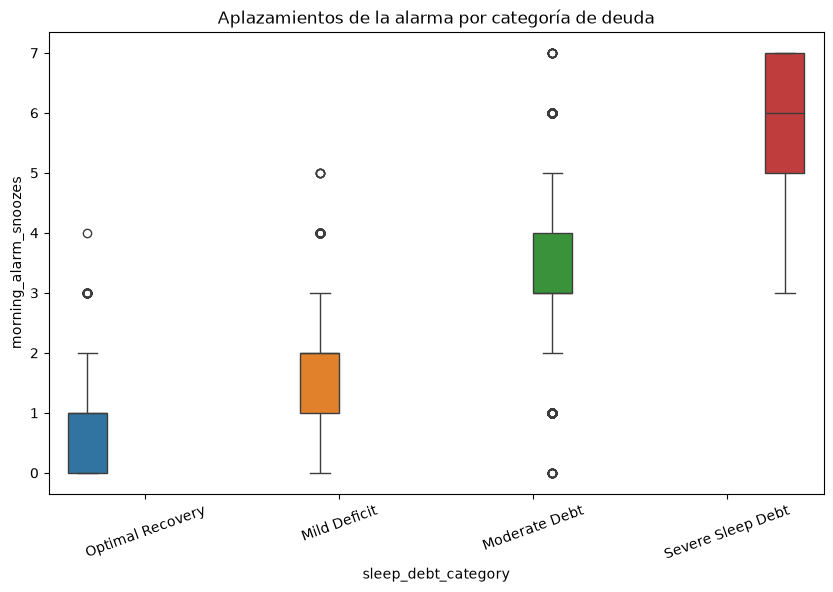

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='sleep_debt_category', y='morning_alarm_snoozes', hue="sleep_debt_category")
plt.xticks(rotation=20)
plt.title("Aplazamientos de la alarma por categoría de deuda")
plt.show()

Se ve un comportamiento contrario al de `total_sleep_hours`. A medida que aumenta la deuda de sueño, también aumentan los aplazamientos de la alarma.

`Optimal Recovery` se concentra principalmente en valores bajos, mientras que `Severe Sleep Debt` presenta valores más altos. Así  que `morning_alarm_snoozes` también podría ayudar a diferenciar las categorías.

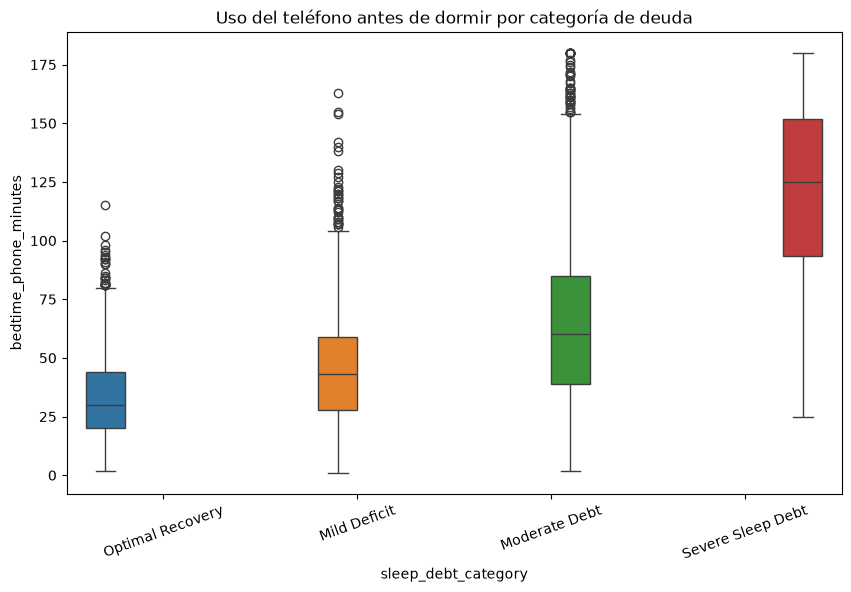

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="sleep_debt_category", y="bedtime_phone_minutes", hue="sleep_debt_category")
plt.xticks(rotation=20)
plt.title("Uso del teléfono antes de dormir por categoría de deuda")
plt.show()

Se observa que conforme aumenta el tiempo de uso del teléfono antes de dormir, también aumenta el nivel de deuda de sueño.

Sin embargo, las cajas presentan más traslape entre categorías que en `total_sleep_hours` o `morning_alarm_snoozes`, haciendo la diferencia no tan marcada.

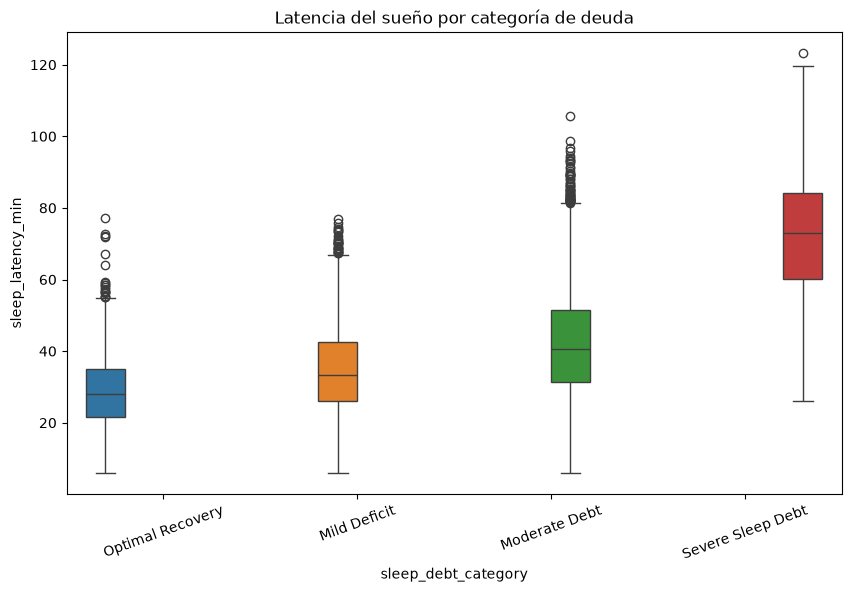

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="sleep_debt_category", y="sleep_latency_min", hue="sleep_debt_category")
plt.xticks(rotation=20)
plt.title("Latencia del sueño por categoría de deuda")
plt.show()

Se observa un patrón parecido al anterior. Conforme aumenta el tiempo necesario para quedarse dormido (latencia), también aumenta el nivel de deuda de sueño.

Aun así, las categorías presentan más traslapes que las anteriores.

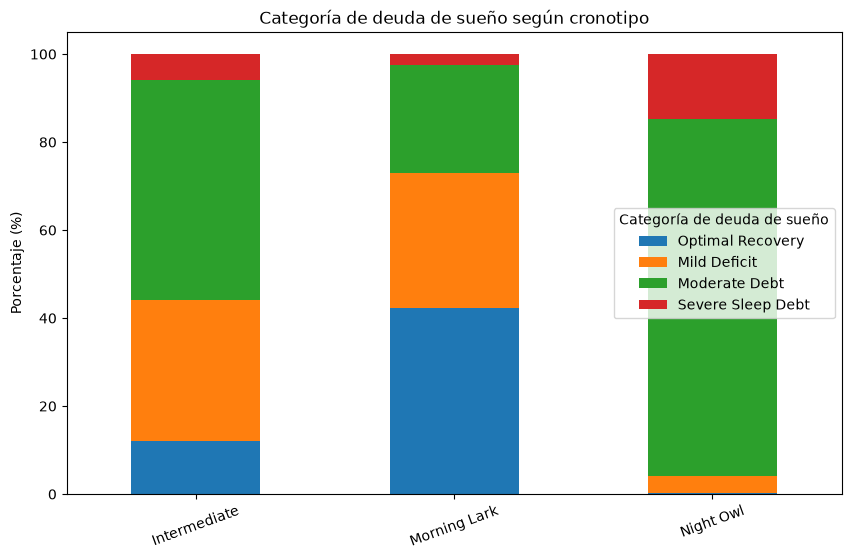

In [31]:
tabla = pd.crosstab(df["chronotype"], df["sleep_debt_category"], normalize="index") * 100
tabla.plot(kind="bar", stacked=True, figsize=(10,6))
plt.ylabel("Porcentaje (%)")
plt.xlabel("")
plt.title("Categoría de deuda de sueño según cronotipo")
plt.xticks(rotation=20)
plt.legend(title="Categoría de deuda de sueño")
plt.show()

Se ve que la distribución de la deuda de sueño cambia según el cronotipo.

En `Morning Lark` las categorías aparecen en proporciones más similares, excepto `Severe Sleep Debt`, que tiene menor presencia.

En `Intermediate` se observa mayor presencia de `Moderate Debt` y también aumenta la proporción de `Severe Sleep Debt`.

En `Night Owl` casi no se observan registros de `Optimal Recovery` (pequeña franja azul en la base de la barra), mientras que predominan los niveles de deuda más altos.

`chronotype` parece ser una variable útil para el modelo.

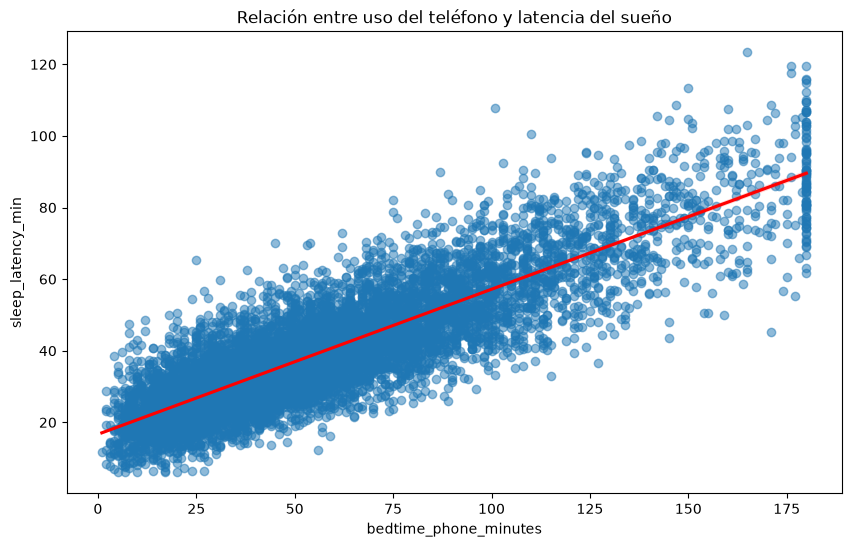

In [32]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='bedtime_phone_minutes', y='sleep_latency_min', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title("Relación entre uso del teléfono y latencia del sueño")
plt.show()

Se observa una relación lineal positiva entre `bedtime_phone_minutes` y `sleep_latency_min`. A medida que aumenta el tiempo de uso del teléfono antes de dormir, también tiende a aumentar el tiempo necesario para conciliar el sueño.

La relación se ve bastante clara, por lo que ambas variables parecen estar fuertemente relacionadas.

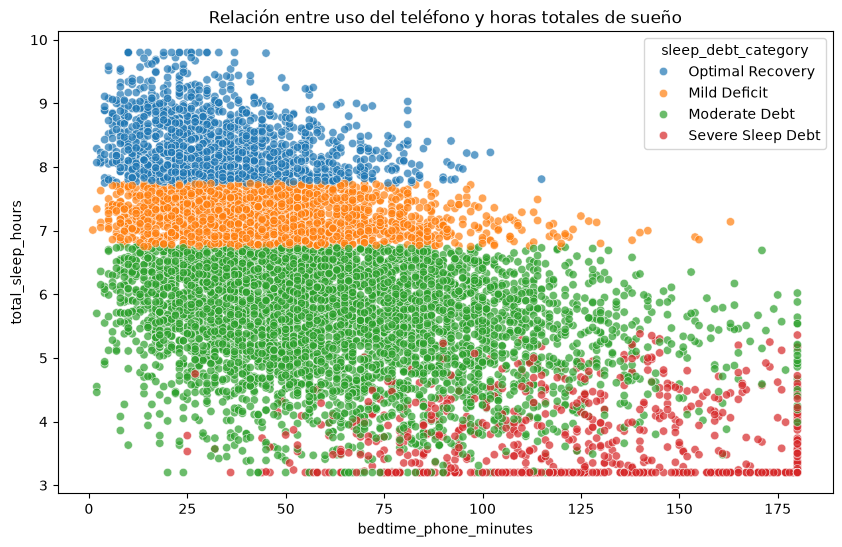

In [33]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='bedtime_phone_minutes', y='total_sleep_hours', hue='sleep_debt_category', alpha=0.7)
plt.title("Relación entre uso del teléfono y horas totales de sueño")
plt.show()

Se observa una relación negativa entre `bedtime_phone_minutes` y `total_sleep_hours`. En general, conforme aumenta el tiempo de uso del teléfono antes de dormir, las horas totales de sueño tienden a disminuir.

También se ve que las categorías con mayor deuda de sueño se concentran principalmente en valores más bajos de horas de sueño, mientras que `Optimal Recovery` aparece en la zona con mayor duración del sueño.

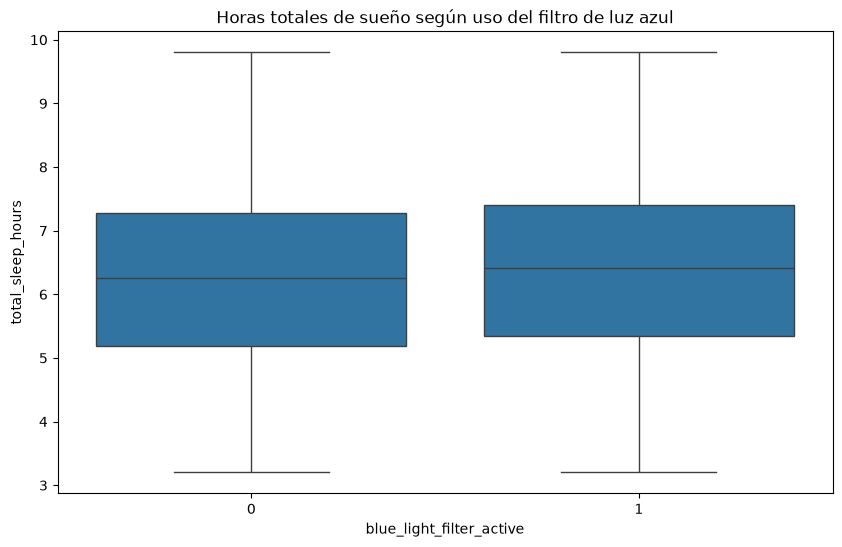

In [34]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='blue_light_filter_active', y='total_sleep_hours')
plt.title("Horas totales de sueño según uso del filtro de luz azul")
plt.show()

Se ve que el uso del filtro de luz azul no genera una diferencia clara en las horas totales de sueño. Ambos grupos presentan distribuciones muy similares.

Por sí sola, esta variable no parece separar de manera importante la duración del sueño.

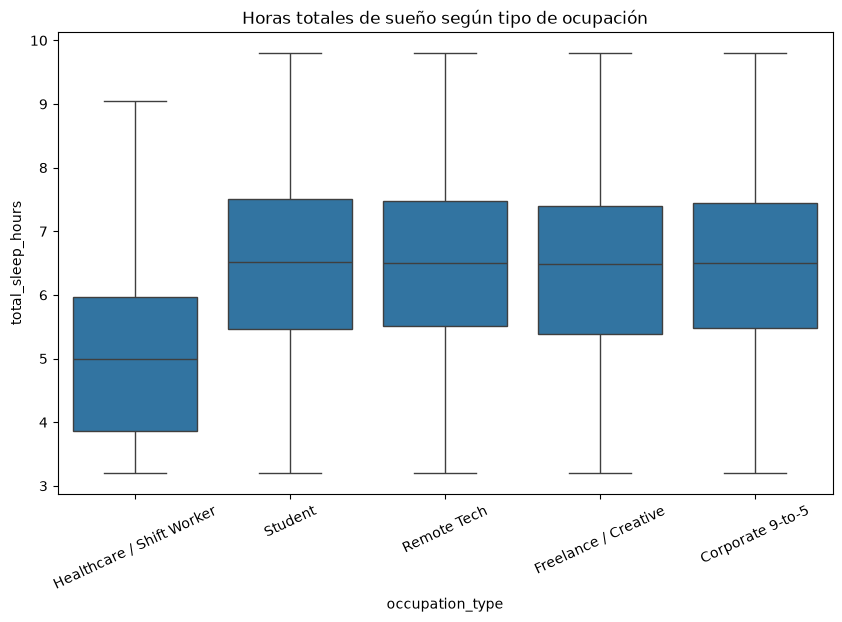

In [35]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='occupation_type', y='total_sleep_hours')
plt.xticks(rotation=25)
plt.title("Horas totales de sueño según tipo de ocupación")
plt.show()

`Healthcare / Shift Worker` presenta valores más bajos de horas de sueño, mientras que los demás grupos tienen distribuciones más parecidas entre sí.

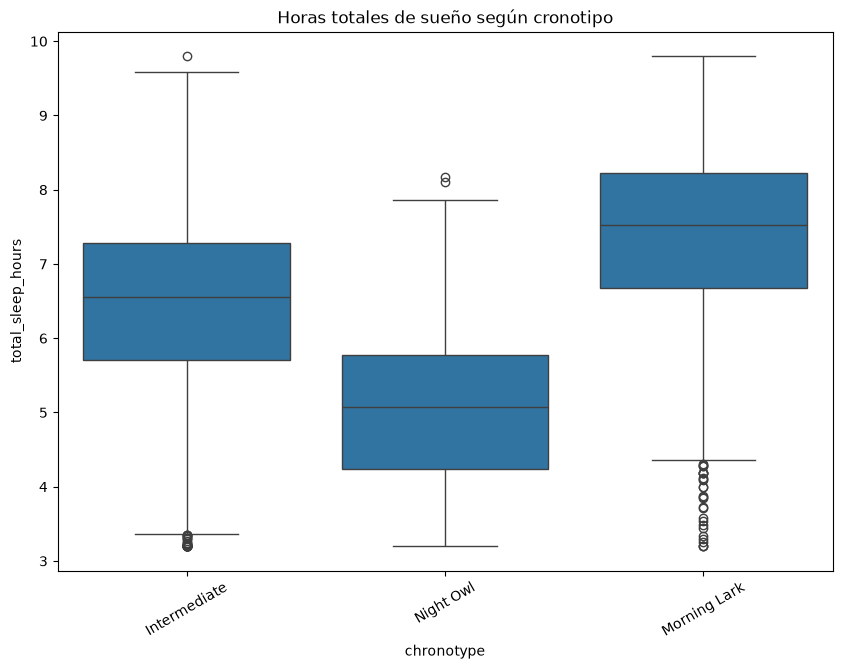

In [36]:
fig = plt.figure(figsize=(10,7))
sns.boxplot(data=df, x='chronotype', y='total_sleep_hours')
plt.xticks(rotation=30)
plt.title("Horas totales de sueño según cronotipo")
plt.show()

Se ve una diferencia clara entre los cronotipos. `Night Owl` presenta menos horas de sueño, `Intermediate` queda en un nivel intermedio y `Morning Lark` muestra los valores más altos.

Esto coincide con lo observado anteriormente en la distribución de `sleep_debt_category`, por lo que `chronotype` parece ser una variable relevante para el modelo.

## Análisis multivariado

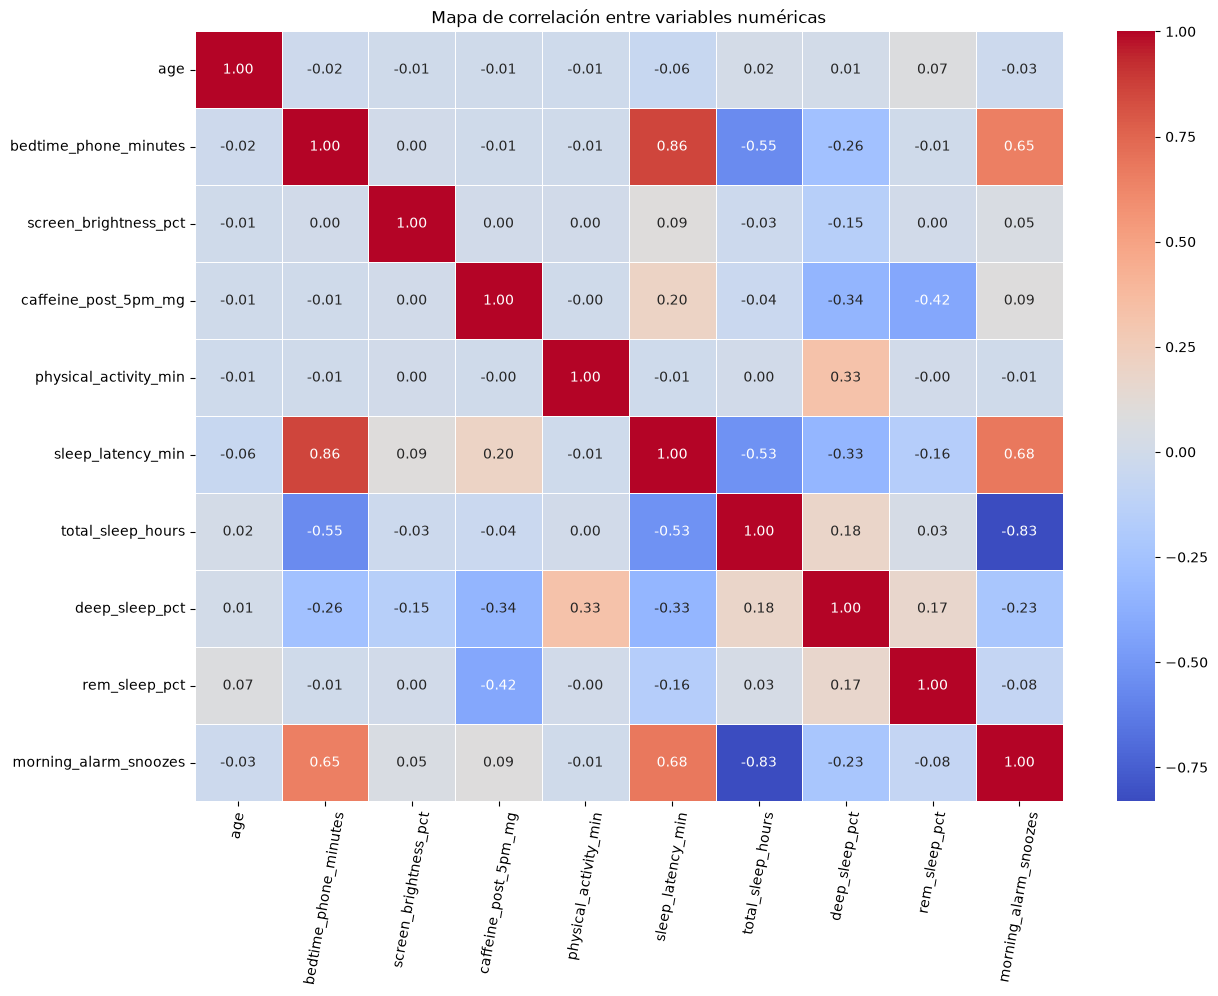

In [37]:
fig = plt.figure(figsize=(14,10))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Mapa de correlación entre variables numéricas")
plt.xticks(rotation=80)
plt.show()

El mapa de correlación muestra varias relaciones importantes:

* La relación positiva más fuerte se observa entre `bedtime_phone_minutes` y `sleep_latency_min` con una correlación de **0.86**. Esto confirma lo visto anteriormente: conforme aumenta el uso del teléfono antes de dormir, también tiende a aumentar el tiempo necesario para conciliar el sueño.

* También se tiene una relación positiva entre `sleep_latency_min` y `morning_alarm_snoozes` (**0.68**) y entre `bedtime_phone_minutes` y `morning_alarm_snoozes` (**0.65**). Esto indica que, en general, una mayor latencia del sueño y un mayor uso del teléfono antes de dormir tienden a relacionarse con más aplazamientos de la alarma.

* Por otro lado, `total_sleep_hours` presenta una relación negativa fuerte con `morning_alarm_snoozes` (**-0.83**), además de relaciones negativas con `bedtime_phone_minutes` (**-0.55**) y `sleep_latency_min` (**-0.53**). Esto indica que menos horas de sueño tienden a relacionarse con mayor uso del teléfono, mayor latencia y más aplazamientos de la alarma.

La correlación alta entre `bedtime_phone_minutes` y `sleep_latency_min` puede generar cierta redundancia entre variables, pero por ahora se mantendrán para construir el baseline.

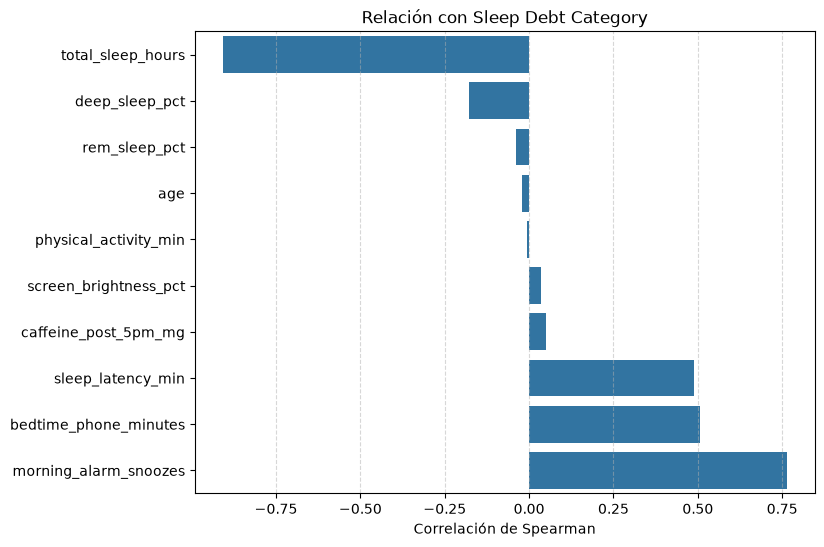

In [38]:
sleep_debt_ordinal = df["sleep_debt_category"].cat.codes

corr_target = (df[num_cols].corrwith(sleep_debt_ordinal, method="spearman").sort_values())

plt.figure(figsize=(8, 6))

sns.barplot(x=corr_target.values, y=corr_target.index)

plt.xlabel("Correlación de Spearman")
plt.ylabel("")
plt.title("Relación con Sleep Debt Category")
plt.grid(True, linestyle="--", alpha=0.5, axis="x")
plt.show()

Al relacionar las variables numéricas con `sleep_debt_category` mediante la correlación de Spearman (mide si dos variables aumentan o disminuyen juntas de forma constante), se ven diferencias claras en la fuerza de las relaciones.

`total_sleep_hours` presenta la relación más fuerte con la variable objetivo (**-0.91**). Esto indica que conforme aumentan las horas de sueño, disminuye el nivel de deuda de sueño.

Por otro lado, `morning_alarm_snoozes` presenta una relación positiva fuerte (**0.76**), mientras que `bedtime_phone_minutes` (**0.51**) y `sleep_latency_min` (**0.49**) muestran relaciones positivas moderadas. Esto coincide con lo observado en las gráficas bivariadas.

Variables como `age`, `screen_brightness_pct`, `physical_activity_min`, `caffeine_post_5pm_mg` y `rem_sleep_pct` presentan relaciones mucho más bajas con la variable objetivo de forma individual.

# Baseline

Para tener un punto de comparación se utilizará primero un `DummyClassifier`. Este modelo no aprende relaciones entre las variables predictoras, sino que genera predicciones siguiendo una estrategia sencilla.

Se probarán diferentes valores del parámetro `strategy` para comparar distintos baselines.

Después se entrenará una regresión logística como un segundo modelo base, utilizando todas las variables predictoras.

Debido al desbalance observado en `sleep_debt_category`, además de `accuracy` se evaluarán `recall_macro`, `f1_macro`, `balanced_accuracy` y `G-Mean`.

En las métricas **macro**, primero se calcula la métrica para cada clase y después se obtiene el promedio, dando el mismo peso a todas las categorías. Esto ayuda a evitar que la clase mayoritaria domine la evaluación.

También se revisará la matriz de confusión de cada corrida para identificar en qué clases se concentran los errores.

In [39]:
# Predictoras
X = df.drop(columns=["sleep_debt_category"])
# Objetivo
y = df["sleep_debt_category"].astype(str)

In [40]:
# Conjuntos de entrenamiento validacion y prueba
X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.30,random_state=777,stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=777,stratify=y_temp)
# Se estratifica por el desbalance de clases

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (5950, 15)
Validación: (1275, 15)
Prueba: (1275, 15)


Los datos se dividieron en **70% entrenamiento, 15% validación y 15% prueba**. Se utilizó `stratify` para mantener aproximadamente la misma proporción de clases en los tres conjuntos.

In [41]:
# Métricas de evaluación

def evaluar_modelo(y_real, y_pred):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "recall_macro": recall_score(
            y_real,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_real,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_real,
            y_pred
        ),
        "gmean": geometric_mean_score(
            y_real,
            y_pred,
            average="multiclass"
        )
    }

`accuracy` permitirá medir el porcentaje total de aciertos, mientras que `recall_macro`, `f1_macro` y `G-Mean` ayudarán a observar mejor el desempeño entre las diferentes clases.

In [42]:
clases_orden = [
    "Optimal Recovery",
    "Mild Deficit",
    "Moderate Debt",
    "Severe Sleep Debt"
]

def registrar_matriz_confusion(
    y_real,
    y_pred,
    titulo,
    artifact_file,
    mostrar=True
):
    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_real,
        y_pred,
        labels=clases_orden,
        cmap="Blues",
        xticks_rotation=30,
        ax=ax
    )

    ax.set_title(titulo)
    plt.tight_layout()

    # Registrar en MLflow
    mlflow.log_figure(
        fig,
        artifact_file
    )

    # Mostrar también en el notebook
    if mostrar:
        plt.show()

    plt.close(fig)

## DummyClassifier

`DummyClassifier` no utiliza los valores de X para clasificar; su comportamiento depende de y y de la estrategia seleccionada

In [43]:
# Estrategias
dummy_strategies = ["most_frequent","prior","stratified","uniform"]

## Regresión Logística

Se entrenará una regresión logística como un baseline que sí utiliza las variables predictoras.

Ya que el dataset tiene variables numéricas y categóricas, se utilizará un `Pipeline` para realizar el preprocesamiento y entrenamiento de forma conjunta.

Las variables numéricas se escalarán con `StandardScaler`, mientras que las variables categóricas se transformarán mediante `OneHotEncoder`.

In [44]:
target = "sleep_debt_category"

numeric_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["str", "category"]
).columns.tolist()

categorical_features.remove(target)

print("Numéricas:")
display(numeric_features)

print("Categóricas:")
display(categorical_features)

Numéricas:


['age',
 'bedtime_phone_minutes',
 'screen_brightness_pct',
 'caffeine_post_5pm_mg',
 'physical_activity_min',
 'sleep_latency_min',
 'total_sleep_hours',
 'deep_sleep_pct',
 'rem_sleep_pct',
 'morning_alarm_snoozes']

Categóricas:


['gender',
 'occupation_type',
 'chronotype',
 'primary_bedtime_app',
 'blue_light_filter_active']

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric_features),
        ("cat",OneHotEncoder(handle_unknown="ignore", drop="first"),categorical_features)
    ]
  )

lr_pipeline = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(max_iter=1000,random_state=777))
    ]
)

2026/10/04 04:37:48 INFO mlflow.tracking.fluent: Experiment with name 'Modelo Base Sleep Debt' does not exist. Creating a new experiment.
2026/10/04 04:37:49 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ fo

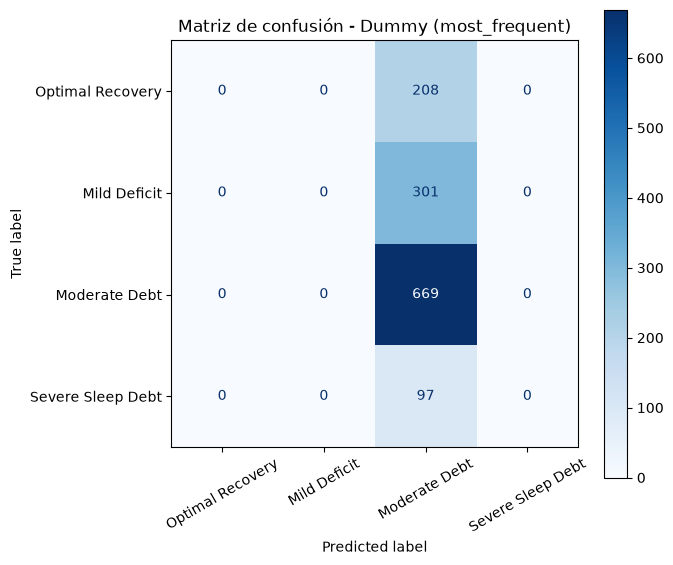

🏃 View run Dummy - most_frequent at: http://127.0.0.1:5000/#/experiments/2/runs/8a6be86bb8024285861fe7e11ca3b5ec
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/10/04 04:37:58 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/04 04:37:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exerc

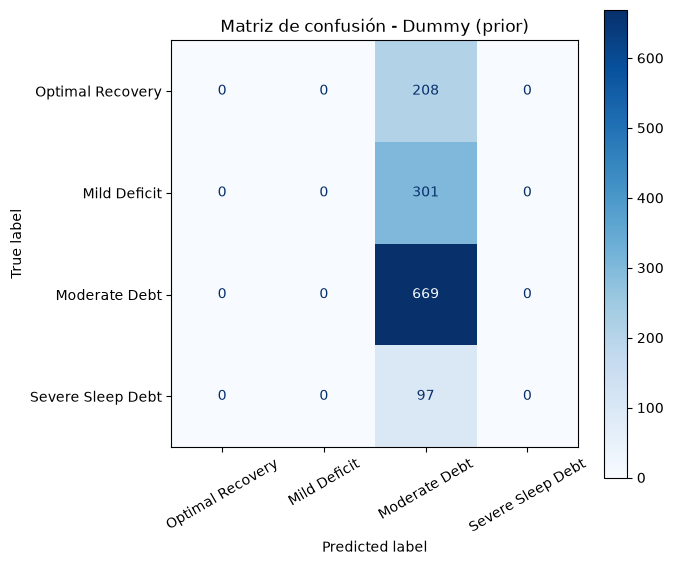

🏃 View run Dummy - prior at: http://127.0.0.1:5000/#/experiments/2/runs/52a5b99505674926812a4dd633e18bd5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/10/04 04:38:04 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/04 04:38:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exerc

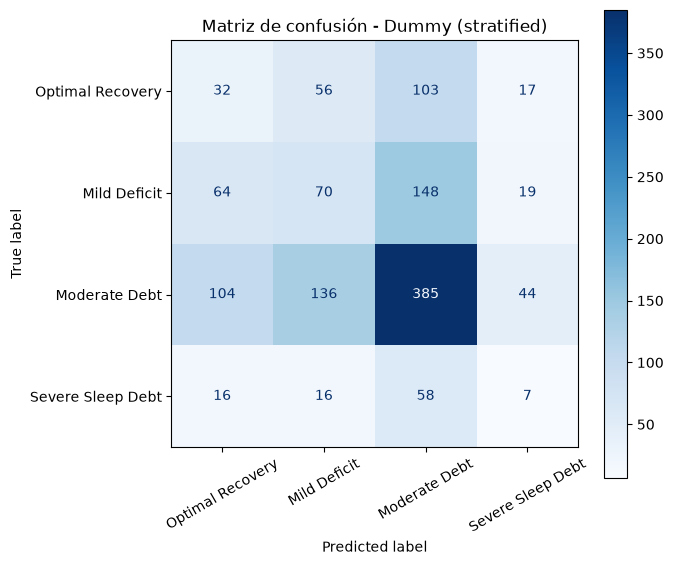

🏃 View run Dummy - stratified at: http://127.0.0.1:5000/#/experiments/2/runs/93025bb6e69a4c168ffe6eea6013f9c7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/10/04 04:38:10 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/04 04:38:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exerc

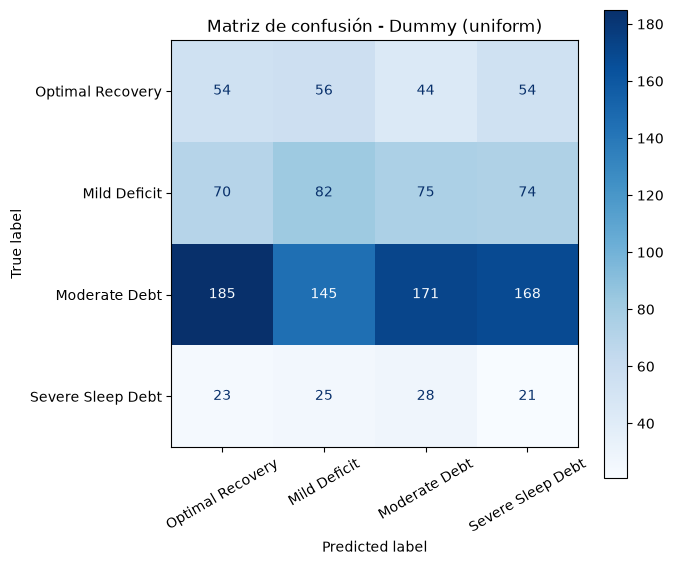

🏃 View run Dummy - uniform at: http://127.0.0.1:5000/#/experiments/2/runs/1fc93a7fcb714e9db495852f608cc4bb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/10/04 04:38:16 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/04 04:38:16 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Doc

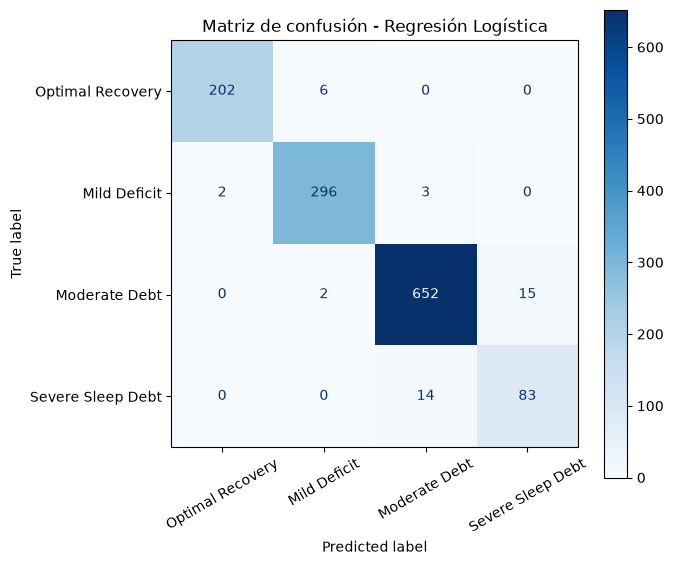

🏃 View run LogisticRegression - validación at: http://127.0.0.1:5000/#/experiments/2/runs/35b301b590e547e18f7013314aeab5ed
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


,modelo,strategy,accuracy,recall_macro,f1_macro,balanced_accuracy,gmean
0,DummyClassifier,most_frequent,0.524706,0.250000,0.172068,0.250000,0.000000
1,DummyClassifier,prior,0.524706,0.250000,0.172068,0.250000,0.000000
2,DummyClassifier,stratified,0.387451,0.258514,0.258439,0.258514,0.196334
3,DummyClassifier,uniform,0.257255,0.251035,0.229312,0.251035,0.250120
4,LogisticRegression,-,0.967059,0.946200,0.946241,0.946200,0.944681


🏃 View run Comparación modelos base at: http://127.0.0.1:5000/#/experiments/2/runs/045c7a2966a645a88d1953c48fc932a5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [46]:
# Configuración de MLflow
mlflow.set_tracking_uri(uri="http://127.0.0.1:5000")

mlflow.set_experiment("Modelo Base Sleep Debt")

# Autolog
mlflow.sklearn.autolog(log_post_training_metrics=False)

# Resultados de TODOS los modelos
resultados_comparacion = []


# ============================================================
# COMPARACIÓN DE MODELOS BASE
# ============================================================

with mlflow.start_run(run_name="Comparación modelos base"):
    mlflow.set_tag(
        "etapa",
        "validacion")

    # ========================================================
    # DUMMY CLASSIFIER
    # ========================================================

    for strategy in dummy_strategies:

        with mlflow.start_run(run_name=f"Dummy - {strategy}",nested=True):

            mlflow.set_tag(
                "tipo_modelo",
                "DummyClassifier"
            )

            mlflow.set_tag(
                "etapa",
                "validacion"
            )

            mlflow.log_param(
                "split_evaluacion",
                "validation"
            )

            dummy = DummyClassifier(
                strategy=strategy,
                random_state=777
            )

            dummy.fit(
                X_train,
                y_train
            )

            # Predicción sobre validación
            y_pred = dummy.predict(
                X_val
            )

            # Métricas
            metricas = evaluar_modelo(
                y_val,
                y_pred
            )

            mlflow.log_metrics(
                metricas
            )

            # Guardar resultados
            resultados_comparacion.append({
                "modelo": "DummyClassifier",
                "strategy": strategy,
                **metricas
            })

            # Predicciones a df
            resultados = pd.DataFrame({
                "Valor_Real": y_val,
                "Prediccion": y_pred
            })

            file_name = f"pred_dummy_{strategy}.csv"

            resultados.to_csv(
                file_name,
                index=False
            )

            mlflow.log_artifact(
                file_name,
                artifact_path="results"
            )

            # Matriz de confusión
            registrar_matriz_confusion(
                y_val,
                y_pred,
                f"Matriz de confusión - Dummy ({strategy})",
                f"confusion_matrix/dummy_{strategy}.png",
                mostrar=True
            )


    # ========================================================
    # REGRESIÓN LOGÍSTICA
    # ========================================================

    with mlflow.start_run(run_name="LogisticRegression - validación", nested=True):

        mlflow.set_tag(
            "tipo_modelo",
            "LogisticRegression"
        )

        mlflow.set_tag(
            "etapa",
            "validacion"
        )

        mlflow.log_param(
            "split_evaluacion",
            "validation"
        )

        lr_pipeline.fit(
            X_train,
            y_train
        )

        # Predicción
        y_pred_lr = lr_pipeline.predict(
            X_val
        )

        # Métricas
        metricas_lr = evaluar_modelo(
            y_val,
            y_pred_lr
        )

        mlflow.log_metrics(
            metricas_lr
        )

        # Guardar resultados
        resultados_comparacion.append({
            "modelo": "LogisticRegression",
            "strategy": "-",
            **metricas_lr
        })

        # Predicciones a df
        resultados_lr = pd.DataFrame({
            "Valor_Real": y_val,
            "Prediccion": y_pred_lr
        })

        file_name = "pred_logistic_regression.csv"

        resultados_lr.to_csv(
            file_name,
            index=False
        )

        mlflow.log_artifact(
            file_name,
            artifact_path="results"
        )

        # Matriz de confusión
        registrar_matriz_confusion(
            y_val,
            y_pred_lr,
            "Matriz de confusión - Regresión Logística",
            "confusion_matrix/logistic_regression.png",
            mostrar=True
        )


    # ========================================================
    # RESUMEN DE LA COMPARACIÓN EN LA RUN PADRE
    # ========================================================

    comparacion_modelos = pd.DataFrame(
        resultados_comparacion
    )

    # Mostrar resultados
    display(comparacion_modelos)

    # Guardar comparación
    comparacion_modelos.to_csv(
        "comparacion_modelos.csv",
        index=False
    )

    mlflow.log_artifact(
        "comparacion_modelos.csv",
        artifact_path="comparison"
    )

    # Registrar el mejor resultado
    mejor_idx = comparacion_modelos[
        "f1_macro"
    ].idxmax()

    mejor_modelo = comparacion_modelos.loc[
        mejor_idx
    ]

    mlflow.log_param(
        "mejor_modelo_validacion",
        str(mejor_modelo["modelo"])
    )

    mlflow.log_metric(
        "mejor_f1_macro_validacion",
        float(mejor_modelo["f1_macro"])
    )

### Comparación de los modelos base

Los resultados del `DummyClassifier` muestran por qué no conviene evaluar este problema únicamente con `accuracy`. Las estrategias `most_frequent` y `prior` alcanzan una accuracy cercana al **52.5%**, similar a la proporción de la clase mayoritaria, pero su `G-Mean` es **0**, indicando que no reconocen correctamente todas las categorías.

La regresión logística muestra una mejora clara respecto a todas las estrategias del Dummy. En validación obtiene una `accuracy` cercana al **96.7%**, un `recall_macro` de **0.95**, un `f1_macro` de **0.95** y un `G-Mean` de **0.94**.
Es decir, el modelo mantiene un desempeño alto entre las diferentes categorías.

La matriz de confusión permite ver que los principales errores de la regresión logística se presentan entre categorías cercanas, especialmente entre `Moderate Debt` y `Severe Sleep Debt`.

Por lo tanto, se selecciona la regresión logística para realizar la evaluación final sobre el conjunto de prueba.

## Regresión en el conjunto de prueba

2026/10/04 04:38:51 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Documents\Maestria\MLOps\test-project\venv3.14\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/04 04:38:51 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\ingri\Doc

,accuracy,recall_macro,f1_macro,balanced_accuracy,gmean
0,0.974902,0.943137,0.957278,0.943137,0.940004


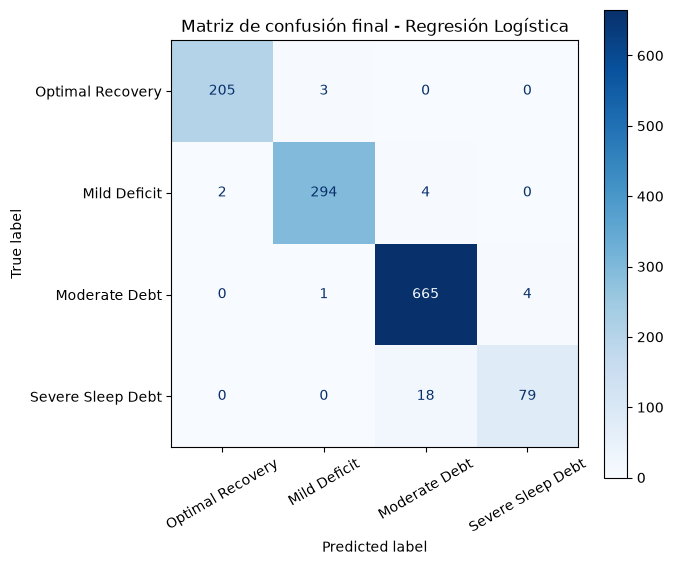

🏃 View run LogisticRegression - evaluación final at: http://127.0.0.1:5000/#/experiments/2/runs/cd46b0bcde214bdd9b3cf318a06c57a0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [47]:
# Unir entrenamiento y validación
X_train_final = pd.concat(
    [X_train, X_val]
)

y_train_final = pd.concat(
    [y_train, y_val]
)

# Crear una copia del Pipeline
lr_pipeline_final = clone(
    lr_pipeline
)


# ============================================================
# REGRESION SOBRE TEST
# ============================================================

with mlflow.start_run(
    run_name="LogisticRegression - evaluación final"
):

    mlflow.set_tag(
        "tipo_modelo",
        "LogisticRegression"
    )

    mlflow.set_tag(
        "etapa",
        "prueba_final"
    )

    mlflow.log_param(
        "split_evaluacion",
        "test"
    )

    lr_pipeline_final.fit(
        X_train_final,
        y_train_final
    )

    # Predicción final
    y_pred_test = lr_pipeline_final.predict(
        X_test
    )

    # Métricas finales
    metricas_test = evaluar_modelo(
        y_test,
        y_pred_test
    )

    mlflow.log_metrics(
        metricas_test
    )

    # Mostrar métricas
    metricas_test_df = pd.DataFrame(
        [metricas_test]
    )

    display(
        metricas_test_df
    )

    # Predicciones finales
    resultados_test = pd.DataFrame({
        "Valor_Real": y_test,
        "Prediccion": y_pred_test
    })

    resultados_test.to_csv(
        "pred_logistic_regression_test.csv",
        index=False
    )

    mlflow.log_artifact(
        "pred_logistic_regression_test.csv",
        artifact_path="results"
    )

    # Matriz de confusión final
    registrar_matriz_confusion(
        y_test,
        y_pred_test,
        "Matriz de confusión final - Regresión Logística",
        "confusion_matrix/logistic_regression_test.png",
        mostrar=True
    )

En la evaluación final sobre el conjunto de prueba, la regresión logística mantiene un desempeño alto, con una `accuracy` cercana al **97.5%**, un `F1-macro` de aproximadamente **0.96** y un `G-Mean` de **0.94**.

Los resultados son similares a los obtenidos durante la validación, por lo que no se observa una caída importante de desempeño al utilizar datos que no participaron en la selección del modelo.

La matriz de confusión muestra nuevamente que la mayor parte de las predicciones se encuentran en la diagonal, aunque permanecen algunos errores entre categorías cercanas de deuda de sueño.

## Reflexión final

En este flujo mejoraría primero la selección de variables. Para el baseline se utilizaron todas las variables predictoras, pero sería interesante comparar el resultado con subconjuntos de variables, por ejemplo las que mostraron mayor relación con la variable objetivo durante el EDA. También probaría otras formas de preprocesamiento, como `MinMaxScaler`, y diferentes configuraciones del modelo para analizar si realmente existe una mejora.

Una de las partes que considero más útiles fue el uso de `Pipeline`, ya que permite mantener en un mismo flujo las transformaciones de los datos y el entrenamiento del modelo. También fue importante utilizar diferentes métricas, porque en un problema con clases desbalanceadas la `accuracy` por sí sola puede dar una idea incompleta del desempeño.

En mi área profesional se comparan distintas configuraciones de modelos, pero parte de este seguimiento puede depender del conocimiento tácito de cada científico de datos. MLflow puede ayudar a reducir este problema al mantener una trazabilidad de parámetros, métricas, modelos y artefactos. Incluso en este ejemplo sencillo se puede seguir cómo se construyó cada experimento y comparar de forma más clara los resultados obtenidos.